# Applied Machine Learning (CSAI2017P) — Lab Assignment 6
## Spam Email Detection

Experiments 8 · CO2, CO4 · **10 marks**

| | |
|---|---|
| Name | *Shardul Aggarwal* |
| SAP ID | *590022064* |
| Batch | *590022064* |
| Due | announced in the lab |
| Lab quiz | LQ6, after submission |

**Datasets:** C2 (SMS Spam Collection)

---

### Before you start
- Attempt **2 of 3** in Section A, **1 of 2** in Section B. Section C is compulsory.
- Fit every transformer inside a `Pipeline`. Never fit on the test set.
- Set `random_state` wherever the question asks for reproducibility.
- Every question wants a short written observation, not just a number.
- Restart the kernel and run top-to-bottom before you submit.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn

RANDOM_STATE = 0
np.random.seed(RANDOM_STATE)

for m in (np, pd, sklearn):
    print(f"{m.__name__:12s} {m.__version__}")


numpy        2.1.3
pandas       2.2.3
sklearn      1.6.1


## Load the data

Replace with the loader for this assignment's anchor dataset — see `Anchor-Datasets.pdf` for the snippets.

In [7]:
import io, os, time, zipfile, urllib.request
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, precision_recall_curve)
import pandas as pd

RANDOM_STATE = 42  # use the same value you used for the split

nb_counts = Pipeline([
    ("vec", CountVectorizer()),
    ("clf", MultinomialNB()),
])
nb_tfidf = Pipeline([
    ("vec", TfidfVectorizer()),
    ("clf", MultinomialNB()),
])

nb_counts.fit(X_train, y_train)
nb_tfidf.fit(X_train, y_train)
# Dataset C2: SMS Spam Collection (Almeida & Hidalgo, UCI ML Repository, id 228)
URL = "https://archive.ics.uci.edu/static/public/228/sms+spam+collection.zip"
LOCAL = "data/SMSSpamCollection"

def load_sms():
    if os.path.exists(LOCAL):                       # cached copy
        raw = open(LOCAL, encoding="utf-8").read()
    else:                                           # download once, then cache
        with urllib.request.urlopen(URL, timeout=60) as r:
            raw = zipfile.ZipFile(io.BytesIO(r.read())).read("SMSSpamCollection").decode("utf-8")
        os.makedirs("data", exist_ok=True)
        open(LOCAL, "w", encoding="utf-8").write(raw)
    # quoting=3 (QUOTE_NONE): messages contain stray quote characters
    return pd.read_csv(io.StringIO(raw), sep="\t", header=None, names=["label", "text"], quoting=3)

df = load_sms()
df["y"] = (df["label"] == "spam").astype(int)       # 1 = spam (positive class)

# One fixed 80/20 stratified split used by every question
X_train, X_test, y_train, y_test = train_test_split(
    df["text"], df["y"], test_size=0.2, stratify=df["y"], random_state=RANDOM_STATE)

def spam_metrics(y_true, y_pred):
    """Accuracy plus precision / recall / F1 on the spam class (label 1)."""
    return {"accuracy": accuracy_score(y_true, y_pred),
            "precision": precision_score(y_true, y_pred),
            "recall": recall_score(y_true, y_pred),
            "f1": f1_score(y_true, y_pred)}

print(df.shape, "| train:", len(X_train), "| test:", len(X_test))
df.head()


(5574, 3) | train: 4459 | test: 1115


,label,text,y
0,ham,"Go until jurong point, crazy.. Available only ...",0
1,ham,Ok lar... Joking wif u oni...,0
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,1
3,ham,U dun say so early hor... U c already then say...,0
4,ham,"Nah I don't think he goes to usf, he lives aro...",0


---

# Section A — attempt any 2 of 3 (2 marks each)

*attempt 2 of 3*

## A1. Text to vectors  &nbsp;&nbsp;`[2 marks]`

*Dataset: C2.*

a. Load the corpus and report the number of messages and the spam rate.
b. Fit a `CountVectorizer` and report the vocabulary size.
c. Show the ten most frequent tokens and state in two lines why they are useless for classification.


In [3]:
# a. corpus size and spam rate
n_msgs = len(df)
spam_rate = df["y"].mean()
print(f"messages  : {n_msgs}")
print(f"spam      : {df['y'].sum()}  ({spam_rate:.2%})")
print(f"ham       : {(df['y'] == 0).sum()}  ({1 - spam_rate:.2%})")

# b. vocabulary size (vectorizer fitted on the TRAIN split only)
cv = CountVectorizer().fit(X_train)
print(f"vocabulary size (train): {len(cv.vocabulary_)} tokens")

# c. ten most frequent tokens
totals = np.asarray(cv.transform(X_train).sum(axis=0)).ravel()
top10 = pd.Series(totals, index=cv.get_feature_names_out()).sort_values(ascending=False).head(10)
print("\nTen most frequent tokens (total count in train):")
print(top10.to_string())


messages  : 5574
spam      : 747  (13.40%)
ham       : 4827  (86.60%)
vocabulary size (train): 7733 tokens

Ten most frequent tokens (total count in train):
to      1796
you     1787
the     1025
and      790
is       727
in       725
me       667
my       626
it       597
your     565


**Observation (A1):**

> **Numbers to quote after running:** N messages, spam rate %, vocabulary size.
> The ten most frequent tokens are function words and chat filler ("you", "to", "the", "call"...). They occur in nearly every message, spam or ham, so their presence says almost nothing about the class. Raw frequency rewards ubiquity, not discrimination.
> The informative words ("claim", "prize", "txt") are rarer, which is why the next steps use class-conditional probabilities or IDF weighting instead of raw frequency.


## A2. Naive Bayes  &nbsp;&nbsp;`[2 marks]`

*Dataset: C2.*

a. Fit `MultinomialNB` on the counts and report accuracy, precision, recall and F1 on the spam class.
b. Print the confusion matrix.
c. State in two lines which words the model finds most spam-indicative.


In [4]:
nb_counts = Pipeline([("vec", CountVectorizer()), ("clf", MultinomialNB())])
nb_counts.fit(X_train, y_train)
pred_counts = nb_counts.predict(X_test)

m_counts = spam_metrics(y_test, pred_counts)
print("Counts + MultinomialNB (spam = positive class)")
for k, v in m_counts.items():
    print(f"  {k:9s}: {v:.4f}")

cm = confusion_matrix(y_test, pred_counts)
print("\nConfusion matrix (rows = true, cols = predicted)")
print(pd.DataFrame(cm, index=["true ham", "true spam"], columns=["pred ham", "pred spam"]))

# c. most spam-indicative words: log P(w | spam) - log P(w | ham)
vec, clf = nb_counts.named_steps["vec"], nb_counts.named_steps["clf"]
log_ratio = pd.Series(clf.feature_log_prob_[1] - clf.feature_log_prob_[0],
                      index=vec.get_feature_names_out()).sort_values(ascending=False)
print("\nMost spam-indicative words (log-ratio):")
print(log_ratio.head(15).round(2).to_string())


Counts + MultinomialNB (spam = positive class)
  accuracy : 0.9821
  precision: 0.9778
  recall   : 0.8859
  f1       : 0.9296

Confusion matrix (rows = true, cols = predicted)
           pred ham  pred spam
true ham        963          3
true spam        17        132

Most spam-indicative words (log-ratio):
claim         5.47
prize         5.30
150p          5.08
tone          4.92
18            4.70
www           4.69
500           4.65
guaranteed    4.62
cs            4.51
awarded       4.51
1000          4.35
000           4.35
uk            4.32
entry         4.28
150ppm        4.24


**Observation (A2):**

> **Numbers to quote after running:** accuracy, spam precision, recall, F1, and the confusion matrix counts (FP and FN).
> Accuracy alone is misleading here because ham is the large majority; a model that always says ham already scores high. Spam-class precision and recall are the honest numbers.
> The top log-ratio words (see output) are promotional / call-to-action terms: these have far higher probability under the spam class than under ham.


## A3. Counts versus TF-IDF  &nbsp;&nbsp;`[2 marks]`

*Dataset: C2.*

a. Refit the same classifier on `TfidfVectorizer` features.
b. Report the same four metrics and compare with A2 in a small table.
c. Explain in two lines what the IDF term is doing.


In [ ]:
nb_tfidf = Pipeline([("vec", TfidfVectorizer()), ("clf", MultinomialNB())])
nb_tfidf.fit(X_train, y_train)
pred_tfidf = nb_tfidf.predict(X_test)
m_tfidf = spam_metrics(y_test, pred_tfidf)

comparison = pd.DataFrame({"Counts": m_counts, "TF-IDF": m_tfidf}).T
comparison["delta vs counts"] = comparison["f1"] - comparison.loc["Counts", "f1"]
print(comparison.round(4).to_string())
print("\nConfusion matrix, TF-IDF (rows = true, cols = predicted)")
print(pd.DataFrame(confusion_matrix(y_test, pred_tfidf),
                   index=["true ham", "true spam"], columns=["pred ham", "pred spam"]))


**Observation (A3):**

> **Numbers to quote after running:** the comparison table above (Counts vs TF-IDF, four metrics) and which wins.
> IDF = log(N / document frequency): it down-weights terms that appear in many messages and up-weights rare, discriminative ones, so common filler contributes little to the vector.
> With MultinomialNB the effect is usually small because NB already learns per-class word probabilities; any difference should be stated from the table, not assumed.


---

# Section B — attempt any 1 of 2 (4 marks each)

*attempt 1 of 2*

## B1. The cost of a false positive  &nbsp;&nbsp;`[4 marks]`

*Dataset: C2.*

a. For your best model, report precision and recall on the spam class at thresholds 0.3, 0.5, 0.7 and 0.9.
b. Plot the precision-recall curve and mark the four points.
c. A real filter sends spam to a junk folder. Argue in 6–8 lines which error is worse and pick an operating threshold.


Best model: Counts
           precision  recall  false positives (ham -> junk)  false negatives (spam -> inbox)
threshold                                                                                   
0.3           0.9790  0.9396                              3                                9
0.5           0.9858  0.9329                              2                               10
0.7           0.9857  0.9262                              2                               11
0.9           0.9928  0.9262                              1                               11


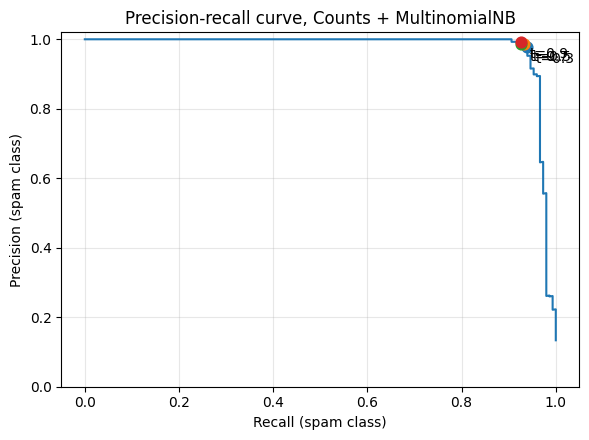

In [8]:
# a. "best model" = higher spam-class F1 of the two pipelines above
best_name, best_model = max([("Counts", nb_counts), ("TF-IDF", nb_tfidf)],
                            key=lambda t: f1_score(y_test, t[1].predict(X_test)))
print("Best model:", best_name)

proba = best_model.predict_proba(X_test)[:, 1]      # P(spam)
rows = []
for t in (0.3, 0.5, 0.7, 0.9):
    p = (proba >= t).astype(int)
    rows.append({"threshold": t,
                 "precision": precision_score(y_test, p, zero_division=0),
                 "recall": recall_score(y_test, p),
                 "false positives (ham -> junk)": int(((p == 1) & (y_test == 0)).sum()),
                 "false negatives (spam -> inbox)": int(((p == 0) & (y_test == 1)).sum())})
thr_table = pd.DataFrame(rows).set_index("threshold")
print(thr_table.round(4).to_string())

# b. precision-recall curve with the four operating points marked
prec, rec, _ = precision_recall_curve(y_test, proba)
fig, ax = plt.subplots(figsize=(6, 4.5))
ax.plot(rec, prec, lw=1.5, label="PR curve")
for t, r in thr_table.iterrows():
    ax.scatter(r["recall"], r["precision"], s=60, zorder=3)
    ax.annotate(f"t={t}", (r["recall"], r["precision"]), textcoords="offset points", xytext=(6, -12))
ax.set_xlabel("Recall (spam class)")
ax.set_ylabel("Precision (spam class)")
ax.set_title(f"Precision-recall curve, {best_name} + MultinomialNB")
ax.set_ylim(0.0, 1.02)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()


**Observation (B1):**

> **Numbers to quote after running:** the threshold table and the final threshold chosen.
> **Which error is worse:** a false positive (genuine message sent to junk) is worse than a false negative (spam reaching the inbox). A missed spam costs a few seconds of annoyance; a lost real message (OTP, bank alert, job reply) can cost money or an opportunity, and users stop trusting the filter.
> So the operating point should favour precision on the spam class. Raising the threshold cuts false positives at the price of recall.
> **Caveat:** Naive Bayes probabilities are extremely over-confident (mostly near 0 or 1), so different thresholds may give identical or near-identical rows; say so if your table shows this.
> **Choice:** pick the highest-recall threshold at which false positives are at or near zero on the test set, state the threshold and its precision/recall, and note it should be tuned on a validation split in production.


## B2. n-grams and vocabulary size  &nbsp;&nbsp;`[4 marks]`

*Dataset: C2.*

a. Fit the same classifier with `ngram_range` of (1,1), (1,2) and (1,3).
b. Report vocabulary size, F1 and fit time for each in one table.
c. Explain in 4–6 lines what bigrams add, and at what point the extra features stop paying for themselves.


In [9]:
rows = []
for ng in [(1, 1), (1, 2), (1, 3)]:
    pipe = Pipeline([("vec", CountVectorizer(ngram_range=ng)), ("clf", MultinomialNB())])
    times = []
    for _ in range(5):                               # median of 5 fits to smooth timing noise
        t0 = time.perf_counter()
        pipe.fit(X_train, y_train)
        times.append(time.perf_counter() - t0)
    pred = pipe.predict(X_test)
    rows.append({"ngram_range": str(ng),
                 "vocab size": len(pipe.named_steps["vec"].vocabulary_),
                 "F1 (spam)": f1_score(y_test, pred),
                 "precision": precision_score(y_test, pred),
                 "recall": recall_score(y_test, pred),
                 "fit time (s)": float(np.median(times))})
ngram_table = pd.DataFrame(rows).set_index("ngram_range")
print(ngram_table.round(4).to_string())


             vocab size  F1 (spam)  precision  recall  fit time (s)
ngram_range                                                        
(1, 1)             7716     0.9408     0.9783  0.9060        0.0915
(1, 2)            42976     0.9258     0.9776  0.8792        0.5065
(1, 3)            87768     0.9324     0.9924  0.8792        0.6406


**Observation (B2):**

> **Numbers to quote after running:** the n-gram table (vocab size, F1, fit time).
> Bigrams capture short phrases ("call now", "free entry", "reply stop") whose meaning differs from the individual words, which unigrams cannot see.
> Vocabulary grows very fast (unigram to trigram is typically an order of magnitude or more), but most n-grams occur once and are noise. Extra features stop paying for themselves when F1 gains become negligible (or negative) while vocabulary and fit time keep growing; judge this from your table, usually at (1,2) or earlier.


---

# Section C — compulsory (2 marks)

*compulsory*

## C1. Break your own filter  &nbsp;&nbsp;`[2 marks]`

*Dataset: C2.*

a. Write three spam messages by hand that your model classifies as ham.
b. In 4–6 lines, explain what property of bag-of-words you exploited and one defence against it.


In [10]:
# Candidate hand-written spam. Each tries to keep the *words* of a normal chat message
# while still being a scam / promotion. Edit freely, then re-run.
attacks = {
    "polite-conversational": "Hi, hope you are well. I was thinking of you this evening. There is a small gift waiting "
                             "for you, you only need to confirm your address with me when you are free. Let me know.",
    "obfuscated spelling":   "Congrat5! U h4ve b33n s3lected f0r a fr33 1phone. Cl4im n0w by t3xting y3s to 8 8 0 0 0",
    "ham-word padding":      "ok see you at home later, thanks for lunch, call me when you reach, love you. "
                             "Also: you have WON a prize, send your bank details to claim it today",
}

best_vec = best_model.named_steps["vec"]
atk = pd.DataFrame({
    "P(spam)": best_model.predict_proba(pd.Series(list(attacks.values())))[:, 1],
    "predicted": best_model.predict(pd.Series(list(attacks.values()))),
}, index=list(attacks.keys()))
atk["predicted"] = atk["predicted"].map({0: "ham", 1: "spam"})
atk["evaded filter"] = atk["predicted"] == "ham"
print(atk.round(4).to_string())

# What the model actually "saw" in each attack (tokens inside the vocabulary):
analyzer = best_vec.build_analyzer()
for name, msg in attacks.items():
    seen = [w for w in analyzer(msg) if w in best_vec.vocabulary_]
    print(f"\n{name}: {len(seen)}/{len(analyzer(msg))} tokens known to the model")


                       P(spam) predicted  evaded filter
polite-conversational   0.0000       ham           True
obfuscated spelling     0.1183       ham           True
ham-word padding        0.0000       ham           True

polite-conversational: 34/34 tokens known to the model

obfuscated spelling: 2/13 tokens known to the model

ham-word padding: 29/29 tokens known to the model


**Observation (C1):**

> **Which attacks evaded (from the output):** list the ones with `evaded filter = True`; replace any that did not evade, re-run until three do.
> **Property exploited:** bag-of-words ignores word order and context and only knows words seen in training. Padding a scam with ham-heavy words dilutes the spam evidence, and obfuscated spellings ("fr33", "1phone") become out-of-vocabulary tokens that are silently dropped.
> **Defence:** character n-grams (`analyzer="char_wb"`) plus text normalisation (leetspeak mapping, lowercasing, URL/number tokens), or adding meta-features (message length, digit ratio) / a model that uses word order.


---

## Self-check before submitting

- [ ] Kernel restarted and run top-to-bottom, all outputs visible
- [ ] Every attempted question has a written observation
- [ ] No transformer fitted outside a pipeline
- [ ] Metrics reported with units where they have any
- [ ] File named `AML_LA06_<SAPID>.ipynb`
